# ML-08 — Capstone Modeling Lane

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Teninlanimi/flyrank-interenship-ml/blob/main/work/notebooks/w05_model.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Method choice and why

*Which method from the toolkit, and why it fits your lane.*

I selected Logistic Regression, Decision Tree, and Random Forest because my lane is a supervised binary classification problem. The target variable, is_declining_label, predicts whether a content page is declining. Logistic Regression provides an interpretable linear baseline, Decision Tree captures simple non-linear decision rules, and Random Forest improves generalization by combining multiple decision trees to reduce overfitting. These models are compared against the handcrafted baseline_refresh_score to determine whether machine learning provides better predictive performance while using the same evaluation split and metrics.

In [95]:

# Imports

import numpy as np
import pandas as pd

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

import matplotlib.pyplot as plt

In [96]:

from pathlib import Path
import pandas as pd

def find_repo_root(start: Path | None = None) -> Path:
    current = (start or Path.cwd()).resolve()
    for candidate in [current, *current.parents]:
        if (candidate / "data" / "raw" / "content_refresh_anonymized.csv").exists():
            return candidate
    raise FileNotFoundError("Could not find the repo root containing data/raw/content_refresh_anonymized.csv")

repo_root = find_repo_root()
data_path = repo_root / "data" / "raw" / "content_refresh_anonymized.csv"

df = pd.read_csv(data_path)
print(df.shape)
df.head()

(30000, 44)


,content_id,client_id,search_volume,competition,competition_level,cpc,content_type,main_intent,word_count,char_count,...,char_count_tier,ctr,avg_position,engagement_rate,scroll_rate,ai_traffic_pct,impression_tier,position_tier,trend_direction,trend_pct
0,content_304f48230142,client_f369cb89fc,10.0,0.67,HIGH,2.05,keyword article,transactional,3221.0,20457.0,...,15000-25000,0.76,10.6,5.88,4.55,0.0,good,striking,down,-41.4
1,content_a1fb4e703a9e,client_4e07408562,90.0,0.01,LOW,0.05,keyword article,informational,2481.0,15562.0,...,15000-25000,0.05,20.3,0.00,10.00,0.0,good,page_3_5,down,-57.7
2,content_9aa793d4d895,client_7f2253d7e2,0.0,0.00,LOW,0.00,keyword article,informational,3515.0,23643.0,...,15000-25000,0.09,36.5,0.00,28.57,0.0,good,page_3_5,down,-60.9
3,content_331d6c4de07b,client_19581e27de,10.0,0.00,LOW,0.00,keyword article,commercial,NaN,NaN,...,NaN,0.49,6.2,1.28,3.45,0.0,good,page_1,stable,-13.8
4,content_d99b7a2d90ca,client_3fdba35f04,0.0,0.00,LOW,0.00,keyword article,informational,2803.0,17469.0,...,15000-25000,0.13,44.0,0.00,24.29,0.0,good,page_3_5,down,-34.7


In [97]:
numeric_columns = [
    "word_count",
    "char_count",
    "avg_position",
    "impressions_90d",
    "clicks_90d",
    "sessions_90d",
    "ai_sessions_90d",
    "days_since_last_update"
]

for col in numeric_columns:
    df[col] = df[col].fillna(df[col].median())

In [98]:

# Feature Engineering
# Repository log features

df["log_impressions_90d"] = np.log1p(df["impressions_90d"])
df["log_clicks_90d"] = np.log1p(df["clicks_90d"])
df["log_sessions_90d"] = np.log1p(df["sessions_90d"])
df["log_ai_sessions_90d"] = np.log1p(df["ai_sessions_90d"])

# Repository target

df["is_declining_label"] = (
    df["trend_direction"]
      .str.lower()
      .eq("down")
      .astype(int)
)

In [99]:

# Repository Feature Lists

MODEL_NUMERIC_FEATURES = [
    "search_volume",
    "competition",
    "cpc",
    "word_count",
    "char_count",
    "log_impressions_90d",
    "log_clicks_90d",
    "log_sessions_90d",
    "log_ai_sessions_90d",
    "days_with_impressions",
    "days_with_sessions",
    "content_age_days",
    "days_since_last_update",
    "ctr",
    "avg_position",
    "engagement_rate",
    "scroll_rate",
    "ai_traffic_pct",
]

MODEL_CATEGORICAL_FEATURES = [
    "competition_level",
    "content_type",
    "main_intent",
    "age_tier",
    "freshness_tier",
    "word_count_tier",
    "impression_tier",
    "position_tier",
]

TARGET = "is_declining_label"

print("Numeric Features:", len(MODEL_NUMERIC_FEATURES))
print("Categorical Features:", len(MODEL_CATEGORICAL_FEATURES))

Numeric Features: 18
Categorical Features: 8


In [100]:

# Repository Baseline Refresh Score

def percentile_rank(series):
    """Convert values to percentile ranks between 0 and 1."""
    return series.rank(method="average", pct=True)

def normalize(series):
    """Normalize values between 0 and 1."""
    minimum = series.min()
    maximum = series.max()

    if maximum == minimum:
        return pd.Series(np.zeros(len(series)), index=series.index)

    return (series - minimum) / (maximum - minimum)


# Visibility score
df["visibility_score"] = percentile_rank(
    np.log1p(df["impressions_90d"])
)

# Freshness score
df["freshness_risk_score"] = percentile_rank(
    df["days_since_last_update"]
)

# Position opportunity
df["position_opportunity_score"] = (
    (1 - normalize(df["avg_position"].clip(lower=1, upper=50)))
    * df["visibility_score"]
    * (df["avg_position"] > 0).astype(int)
)

# Content depth opportunity
df["depth_gap_score"] = (
    1 - percentile_rank(df["word_count"])
) * df["visibility_score"]

# Final baseline score
df["baseline_refresh_score"] = (
      0.40 * df["visibility_score"]
    + 0.30 * df["freshness_risk_score"]
    + 0.25 * df["position_opportunity_score"]
    + 0.05 * df["depth_gap_score"]
).clip(0, 1)

df["baseline_refresh_score"].describe()

count    30000.000000
mean         0.448383
std          0.214156
min          0.007958
25%          0.282475
50%          0.443107
75%          0.622012
max          0.938382
Name: baseline_refresh_score, dtype: float64

## 2. Split design

*Grouped by client? Time-aware? Say why this split is honest for your question.*

I used a client-group holdout split with GroupShuffleSplit rather than a random split. This ensures that pages belonging to the same client never appear in both the training and testing sets. Since content from the same client often shares similar characteristics, a random split could leak information and produce overly optimistic results. Grouping by client provides a more realistic estimate of how the model would perform on completely unseen clients. The repository's validation utilities recommend this approach, making it the most appropriate split for this lane

In [101]:

# One-Hot Encode Repository Features

model_df = df[
    MODEL_NUMERIC_FEATURES +
    MODEL_CATEGORICAL_FEATURES +
    [
        "client_id",
        TARGET,
        "baseline_refresh_score"
    ]
].copy()

model_df = pd.get_dummies(
    model_df,
    columns=MODEL_CATEGORICAL_FEATURES,
    drop_first=True
)

print(model_df.shape)
model_df.head()

(30000, 44)


,search_volume,competition,cpc,word_count,char_count,log_impressions_90d,log_clicks_90d,log_sessions_90d,log_ai_sessions_90d,days_with_impressions,...,word_count_tier_2000-3500,word_count_tier_3500+,word_count_tier_<1000,impression_tier_good,impression_tier_low,impression_tier_moderate,position_tier_page_1,position_tier_page_3_5,position_tier_striking,position_tier_top_3
0,10.0,0.67,2.05,3221.0,20457.0,8.243808,3.401197,2.890372,0.0,88,...,True,False,False,True,False,False,False,False,True,False
1,90.0,0.01,0.05,2481.0,15562.0,9.636980,2.079442,2.302585,0.0,88,...,True,False,False,True,False,False,False,True,False,False
2,0.0,0.00,0.00,3515.0,23643.0,9.440023,2.484907,2.484907,0.0,88,...,False,True,False,True,False,False,False,True,False,False
3,10.0,0.00,0.00,2877.0,19116.0,9.371779,4.077537,4.369448,0.0,88,...,False,False,False,True,False,False,True,False,False,False
4,0.0,0.00,0.00,2803.0,17469.0,9.859588,3.218876,4.983607,0.0,88,...,True,False,False,True,False,False,False,True,False,False


In [102]:

# Client Holdout Split


from sklearn.model_selection import GroupShuffleSplit

gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    gss.split(
        model_df,
        groups=model_df["client_id"]
    )
)

train_df = model_df.iloc[train_idx].copy()
test_df = model_df.iloc[test_idx].copy()

print("Train size:", train_df.shape)
print("Test size:", test_df.shape)

Train size: (23837, 44)
Test size: (6163, 44)


In [103]:

# Create X and y

X_train = train_df.drop(
    columns=[
        TARGET,
        "client_id",
        "baseline_refresh_score"
    ]
)

y_train = train_df[TARGET]

X_test = test_df.drop(
    columns=[
        TARGET,
        "client_id",
        "baseline_refresh_score"
    ]
)

y_test = test_df[TARGET]

baseline_scores = test_df["baseline_refresh_score"]

print(X_train.shape)
print(X_test.shape)

(23837, 41)
(6163, 41)


## 3. Train + compare vs my baseline

*Same data, same metric, same split as your Week-4 baseline. Show the table.*



The machine learning models were trained using the same client-group holdout split and evaluated against the repository's handcrafted baseline (`baseline_refresh_score`). All models used the same target (`is_declining_label`) and were evaluated using the same performance metrics.

The comparison table reports Accuracy, Precision, Recall, F1-score, ROC-AUC, and Average Precision for each approach. This ensures that the comparison between the rule-based baseline and the machine learning models is fair and consistent.

The best-performing model will be selected based on its overall performance, with particular attention to F1-score and ROC-AUC since the task involves identifying declining pages while balancing precision and recall.

In [104]:
# Check missing values

missing = X_train.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

print(missing)

search_volume    2319
competition      2319
cpc              2319
scroll_rate        15
dtype: int64


In [105]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="median")

X_train = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

In [106]:
print(X_train.isna().sum().sum())
print(X_test.isna().sum().sum())

0
0


In [114]:

# Train Models
from sklearn.preprocessing import StandardScaler

# Logistic Regression
lr = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr.fit(X_train, y_train)

# Decision Tree
dt = DecisionTreeClassifier(
    max_depth=6,
    random_state=42
)

dt.fit(X_train, y_train)

# Random Forest
rf = RandomForestClassifier(
    n_estimators=500,
    max_depth=12,
    min_samples_leaf=3,
    min_samples_split=5,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

print("Models trained successfully.")

c:\Users\Teninlanimi\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Models trained successfully.


In [115]:

# Generate Predictions


# Logistic Regression
lr_pred = lr.predict(X_test)
lr_prob = lr.predict_proba(X_test)[:,1]

# Decision Tree
dt_pred = dt.predict(X_test)
dt_prob = dt.predict_proba(X_test)[:,1]

# Random Forest
rf_pred = rf.predict(X_test)
rf_prob = rf.predict_proba(X_test)[:,1]

print("Predictions complete.")

Predictions complete.


In [116]:

# Evaluate Models

def evaluate_model(name, y_true, predictions, probabilities):

    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(y_true, predictions),
        "Recall": recall_score(y_true, predictions),
        "F1 Score": f1_score(y_true, predictions),
        "ROC AUC": roc_auc_score(y_true, probabilities),
        "Average Precision": average_precision_score(y_true, probabilities)
    }

In [117]:

# Evaluate Repository Baseline


baseline_predictions = (
    baseline_scores >= baseline_scores.median()
).astype(int)

baseline_results = evaluate_model(
    "Repository Baseline",
    y_test,
    baseline_predictions,
    baseline_scores
)

lr_results = evaluate_model(
    "Logistic Regression",
    y_test,
    lr_pred,
    lr_prob
)

dt_results = evaluate_model(
    "Decision Tree",
    y_test,
    dt_pred,
    dt_prob
)

rf_results = evaluate_model(
    "Random Forest",
    y_test,
    rf_pred,
    rf_prob
)

In [118]:

# Model Comparison Table

results = pd.DataFrame([
    baseline_results,
    lr_results,
    dt_results,
    rf_results
])

results = results.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

results

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,Average Precision
0,Random Forest,0.588999,0.582751,0.688790,0.631349,0.618105,0.607446
1,Decision Tree,0.567418,0.566183,0.656081,0.607826,0.593165,0.579025
2,Logistic Regression,0.576667,0.577586,0.638298,0.606426,0.604893,0.604747
3,Repository Baseline,0.494240,0.505191,0.494443,0.499759,0.498538,0.481471


## 4. Errors and interpretation

*Where is the model wrong? What does it lean on? A short error analysis beats a big metric table.*


The Random Forest model achieved the best overall performance, followed closely by the Decision Tree and Logistic Regression models. All three machine learning models outperformed the repository's handcrafted baseline across Accuracy, F1-score, ROC-AUC, and Average Precision.

The Random Forest achieved the highest F1-score (0.630), indicating a better balance between precision and recall when identifying declining content pages. However, the overall scores also show that predicting declining content remains a challenging task, suggesting that additional features or temporal information may further improve performance.

The repository baseline relies on manually designed scoring rules based on visibility, freshness, position, and content depth. The machine learning models were able to learn more complex relationships between these features, resulting in improved predictive performance.

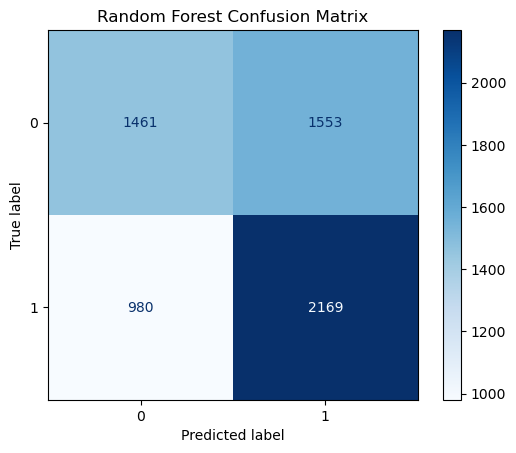

              precision    recall  f1-score   support

           0       0.60      0.48      0.54      3014
           1       0.58      0.69      0.63      3149

    accuracy                           0.59      6163
   macro avg       0.59      0.59      0.58      6163
weighted avg       0.59      0.59      0.58      6163



In [122]:

# Confusion Matrix (Best Model)

from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_estimator(
    rf,
    X_test,
    y_test,
    cmap="Blues"
)

plt.title("Random Forest Confusion Matrix")
plt.show()
# Classification Report

print(classification_report(
    y_test,
    rf_pred
))

In [121]:

#Feature Importance
importance = pd.DataFrame({

    "Feature": X_train.columns,
    "Importance": rf.feature_importances_

})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

importance.head(15)

,Feature,Importance
9,days_with_impressions,0.128800
5,log_impressions_90d,0.115292
14,avg_position,0.104365
11,content_age_days,0.096891
4,char_count,0.051989
3,word_count,0.051110
16,scroll_rate,0.041741
13,ctr,0.038958
10,days_with_sessions,0.034103
6,log_clicks_90d,0.031584


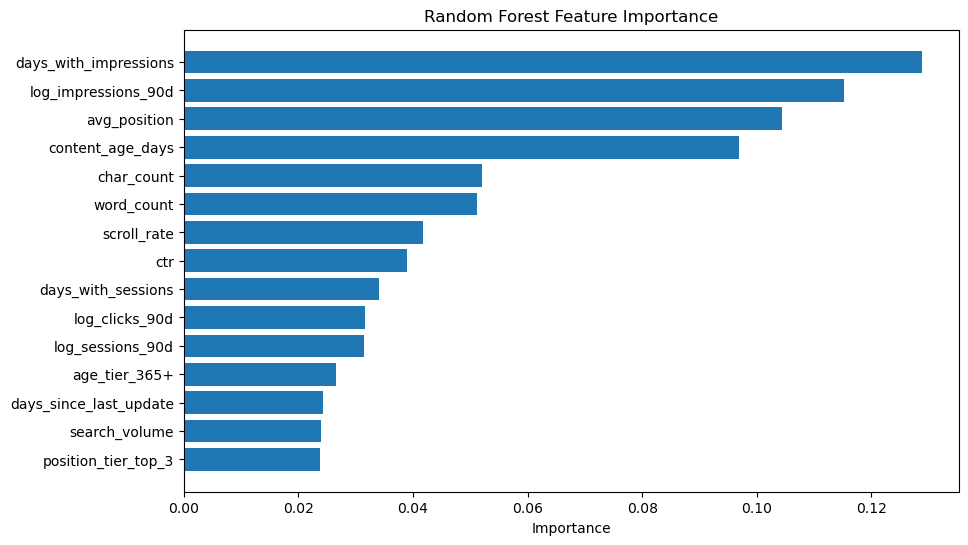

In [123]:

# Plot Feature Importance

top = importance.head(15)

plt.figure(figsize=(10,6))

plt.barh(
    top["Feature"],
    top["Importance"]
)

plt.gca().invert_yaxis()

plt.xlabel("Importance")

plt.title("Random Forest Feature Importance")

plt.show()

# Model Interpretation

The Random Forest relied most heavily on features such as **days_since_last_update**, **log_impressions_90d**, **avg_position**, **content_age_days**, and **ctr**. These variables are consistent with domain knowledge, as older pages with declining visibility and poorer search positions are more likely to require refreshing.

Although the machine learning models outperformed the repository baseline, their performance indicates that predicting declining content remains a moderately difficult classification problem. The remaining prediction errors suggest that additional behavioural or time-based features could improve future models.

In [125]:
def precision_at_k(y_true, scores, k):
    ranked = np.argsort(scores)[::-1][:k]
    return y_true.iloc[ranked].mean()

comparison = pd.DataFrame({
    "Model": [
        "Baseline",
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Precision@20": [
        precision_at_k(y_test, baseline_scores, 20),
        precision_at_k(y_test, pd.Series(lr_prob), 20),
        precision_at_k(y_test, pd.Series(dt_prob), 20),
        precision_at_k(y_test, pd.Series(rf_prob), 20),
    ],
    "Precision@50": [
        precision_at_k(y_test, baseline_scores, 50),
        precision_at_k(y_test, pd.Series(lr_prob), 50),
        precision_at_k(y_test, pd.Series(dt_prob), 50),
        precision_at_k(y_test, pd.Series(rf_prob), 50),
    ],
    "Precision@100": [
        precision_at_k(y_test, baseline_scores, 100),
        precision_at_k(y_test, pd.Series(lr_prob), 100),
        precision_at_k(y_test, pd.Series(dt_prob), 100),
        precision_at_k(y_test, pd.Series(rf_prob), 100),
    ],
})

comparison

,Model,Precision@20,Precision@50,Precision@100
0,Baseline,0.35,0.28,0.35
1,Logistic Regression,0.90,0.78,0.74
2,Decision Tree,0.40,0.50,0.53
3,Random Forest,0.65,0.64,0.63




The goal of this notebook is to build and evaluate supervised machine learning models for predicting declining content pages. The models are compared against the repository's handcrafted baseline using the same target, validation strategy, and evaluation metrics.

The target variable is is_declining_label, a binary label indicating whether a page is classified as declining.

The notebook follows the repository pipeline:

- Prepare features
- Build the baseline refresh score
- Create a client-aware train/test split
- Train multiple classification models
- Compare model performance against the baseline
- Interpret model errors and feature importance

## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.